In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('../datasets/ford.csv')

In [3]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [4]:
df.shape

(17966, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  str    
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  str    
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  str    
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.6 MB


<Axes: xlabel='price', ylabel='Count'>

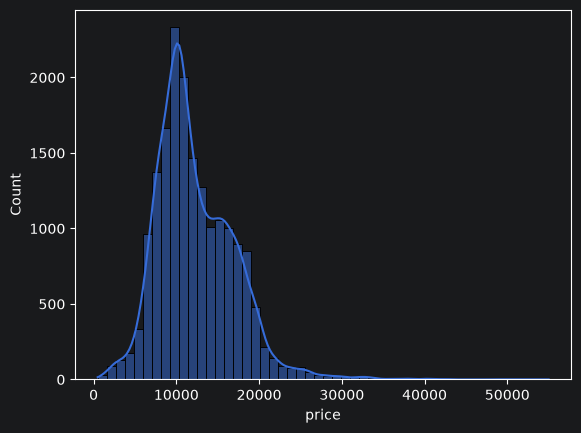

In [6]:
sns.histplot(x=df['price'], kde=True, bins=50)

<Axes: >

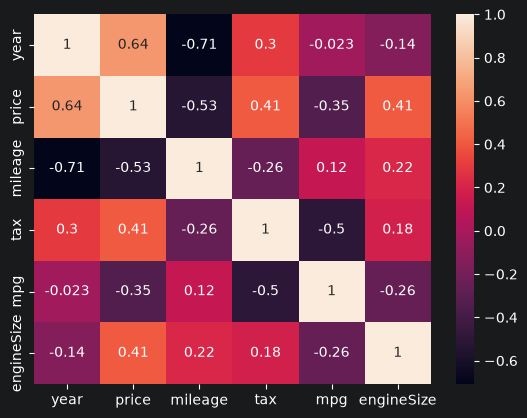

In [7]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, '1996'),
  Text(1, 0, '1998'),
  Text(2, 0, '2000'),
  Text(3, 0, '2002'),
  Text(4, 0, '2003'),
  Text(5, 0, '2004'),
  Text(6, 0, '2005'),
  Text(7, 0, '2006'),
  Text(8, 0, '2007'),
  Text(9, 0, '2008'),
  Text(10, 0, '2009'),
  Text(11, 0, '2010'),
  Text(12, 0, '2011'),
  Text(13, 0, '2012'),
  Text(14, 0, '2013'),
  Text(15, 0, '2014'),
  Text(16, 0, '2015'),
  Text(17, 0, '2016'),
  Text(18, 0, '2017'),
  Text(19, 0, '2018'),
  Text(20, 0, '2019'),
  Text(21, 0, '2020'),
  Text(22, 0, '2060')])

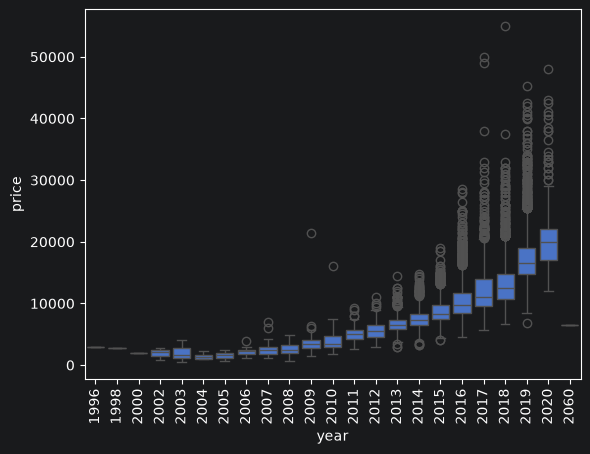

In [8]:
sns.boxplot(data=df, x='year', y='price')
plt.xticks(rotation=90)

<Axes: xlabel='mileage', ylabel='price'>

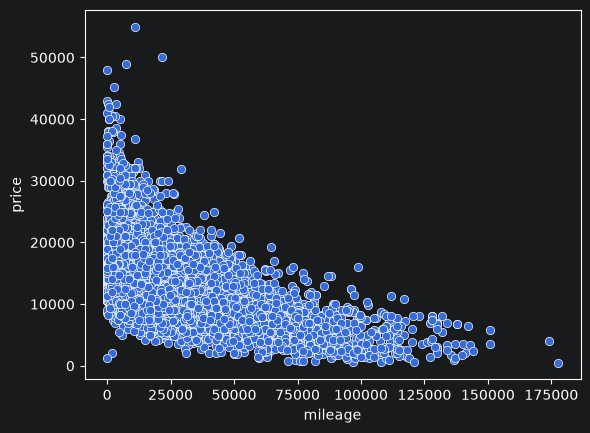

In [9]:
sns.scatterplot(data=df , x='mileage', y='price')

<Axes: xlabel='engineSize', ylabel='price'>

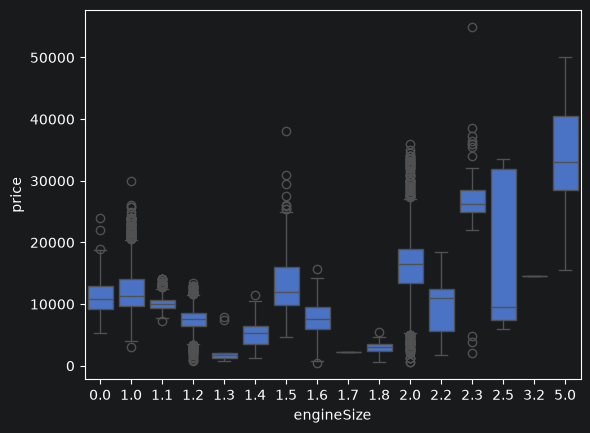

In [10]:
sns.boxplot(data=df, x='engineSize', y='price')

<Axes: xlabel='transmission', ylabel='price'>

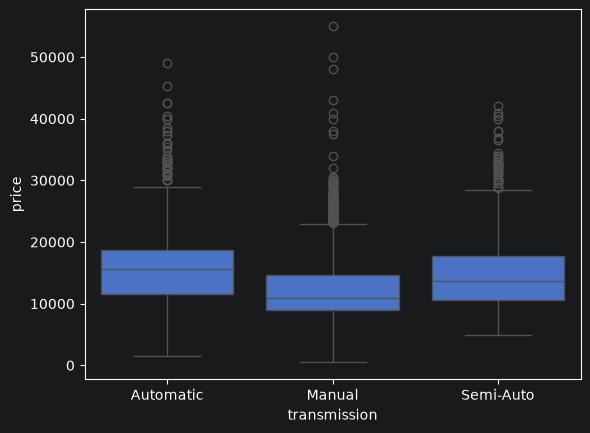

In [11]:
sns.boxplot(data=df, x='transmission', y='price')

<Axes: xlabel='fuelType', ylabel='price'>

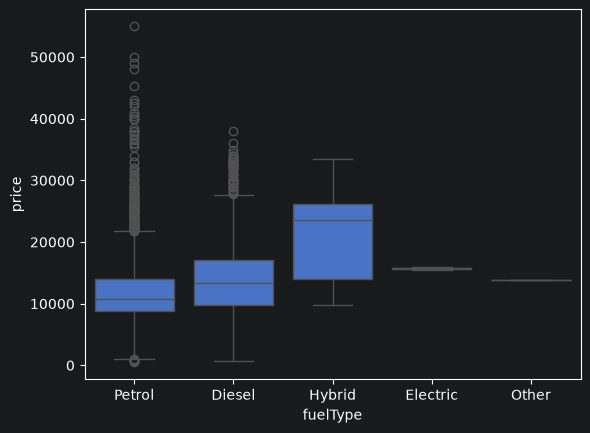

In [12]:
sns.boxplot(data=df, x='fuelType', y='price')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  str    
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  str    
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  str    
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.6 MB


In [14]:
df.shape


(17966, 9)

In [15]:
df_cleaned = df.copy()

In [16]:
df_cleaned.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [17]:
df_cleaned.drop_duplicates(inplace=True)
print(df_cleaned.shape)

(17812, 9)


In [18]:
df_cleaned.isnull().sum()


model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [19]:
df_cleaned.dtypes

model               str
year              int64
price             int64
transmission        str
mileage           int64
fuelType            str
tax               int64
mpg             float64
engineSize      float64
dtype: object

# One Hot Encoding

In [20]:
for col in ['model', 'transmission', 'fuelType']:
    df_cleaned[col] = df_cleaned[col].str.strip()

In [21]:
print(df_cleaned['model'].value_counts())


model
Fiesta                   6509
Focus                    4556
Kuga                     2208
EcoSport                 1127
C-MAX                     542
Ka+                       523
Mondeo                    512
B-MAX                     350
S-MAX                     294
Grand C-MAX               247
Galaxy                    227
Edge                      205
KA                        197
Puma                       79
Tourneo Custom             69
Mustang                    57
Grand Tourneo Connect      57
Tourneo Connect            32
Fusion                     16
Streetka                    2
Ranger                      1
Escort                      1
Transit Tourneo             1
Name: count, dtype: int64


In [22]:
counts = df_cleaned['model'].value_counts()
rare = counts[counts < 20].index


df_cleaned.loc[df_cleaned['model'].isin(rare), 'model'] = 'Others'

In [23]:
print(df_cleaned['model'].value_counts())

model
Fiesta                   6509
Focus                    4556
Kuga                     2208
EcoSport                 1127
C-MAX                     542
Ka+                       523
Mondeo                    512
B-MAX                     350
S-MAX                     294
Grand C-MAX               247
Galaxy                    227
Edge                      205
KA                        197
Puma                       79
Tourneo Custom             69
Mustang                    57
Grand Tourneo Connect      57
Tourneo Connect            32
Others                     21
Name: count, dtype: int64


In [27]:
rare = ['Hybrid', 'Electric', 'Other']
df_cleaned.loc[df_cleaned['fuelType'].isin(rare),'fuelType'] = 'Others'

In [28]:
df_cleaned['fuelType'].value_counts()

fuelType
Petrol    12081
Diesel     5706
Others       25
Name: count, dtype: int64

In [30]:
# To strip the spaces
for col in ['model', 'transmission', 'fuelType']:
    df_cleaned[col] = df_cleaned[col].str.strip()

In [32]:
cat_cols = ['model', 'transmission', 'fuelType']
df_cleaned = pd.get_dummies(df_cleaned, columns=cat_cols, drop_first=True, dtype=int)

In [33]:
df_cleaned.shape

(17812, 28)

In [34]:
df_cleaned.head()

,year,price,mileage,tax,mpg,engineSize,model_C-MAX,model_EcoSport,model_Edge,model_Fiesta,...,model_Mustang,model_Others,model_Puma,model_S-MAX,model_Tourneo Connect,model_Tourneo Custom,transmission_Manual,transmission_Semi-Auto,fuelType_Others,fuelType_Petrol
0,2017,12000,15944,150,57.7,1.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,2018,14000,9083,150,57.7,1.0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
2,2017,13000,12456,150,57.7,1.0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
3,2019,17500,10460,145,40.3,1.5,0,0,0,1,...,0,0,0,0,0,0,1,0,0,1
4,2019,16500,1482,145,48.7,1.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1


In [35]:
df_cleaned.columns

Index(['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize', 'model_C-MAX',
       'model_EcoSport', 'model_Edge', 'model_Fiesta', 'model_Focus',
       'model_Galaxy', 'model_Grand C-MAX', 'model_Grand Tourneo Connect',
       'model_KA', 'model_Ka+', 'model_Kuga', 'model_Mondeo', 'model_Mustang',
       'model_Others', 'model_Puma', 'model_S-MAX', 'model_Tourneo Connect',
       'model_Tourneo Custom', 'transmission_Manual', 'transmission_Semi-Auto',
       'fuelType_Others', 'fuelType_Petrol'],
      dtype='str')

In [36]:
df_cleaned.dtypes

year                             int64
price                            int64
mileage                          int64
tax                              int64
mpg                            float64
engineSize                     float64
model_C-MAX                      int64
model_EcoSport                   int64
model_Edge                       int64
model_Fiesta                     int64
model_Focus                      int64
model_Galaxy                     int64
model_Grand C-MAX                int64
model_Grand Tourneo Connect      int64
model_KA                         int64
model_Ka+                        int64
model_Kuga                       int64
model_Mondeo                     int64
model_Mustang                    int64
model_Others                     int64
model_Puma                       int64
model_S-MAX                      int64
model_Tourneo Connect            int64
model_Tourneo Custom             int64
transmission_Manual              int64
transmission_Semi-Auto   

In [38]:
df_cleaned.head()

,year,price,mileage,tax,mpg,engineSize,model_C-MAX,model_EcoSport,model_Edge,model_Fiesta,...,model_Mustang,model_Others,model_Puma,model_S-MAX,model_Tourneo Connect,model_Tourneo Custom,transmission_Manual,transmission_Semi-Auto,fuelType_Others,fuelType_Petrol
0,2017,12000,15944,150,57.7,1.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,2018,14000,9083,150,57.7,1.0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
2,2017,13000,12456,150,57.7,1.0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
3,2019,17500,10460,145,40.3,1.5,0,0,0,1,...,0,0,0,0,0,0,1,0,0,1
4,2019,16500,1482,145,48.7,1.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1


In [40]:
from sklearn.model_selection import train_test_split


X = df_cleaned.drop('price', axis=1)
y = df_cleaned['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
from sklearn.preprocessing import StandardScaler

num_cols = ['year', 'mileage', 'tax', 'mpg', 'engineSize']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

model = LinearRegression()


In [44]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](27,)","[ 2277.91,-1200.33, -57.55,..., -99.85, 6948.61, -59.33]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](27,)","['year','mileage','tax',...,'transmission_Semi-Auto','fuelType_Others', 'fuelType_Petrol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.049e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,27
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(27)


In [45]:
y_pred = model.predict(X_test)

In [48]:
r2 = r2_score(y_test, y_pred)

In [49]:
n = X_test.shape[0]
p = X_test.shape[1]

In [50]:
adj_r2 = 1 - (1 - r2) * ( n-1 ) / (n-p-1)

In [51]:
print("R2: ", r2)
print("Adjusted R2 : ", adj_r2)

R2:  0.8192247231097045
Adjusted R2 :  0.8178439784205849
